# A Real Amateur Photonics Shop, Analyzed: Beam Optics, Laser Safety, and Cost

[American Photonics](https://shop.americanphotonics.com/) is a genuine
small business — hosted on Shopify at `american-photonics.myshopify.com`
— selling CO2 laser replacement optics to the amateur/hobbyist
laser-cutter community (K40-style machines, Glowforge, and similar).
Real product data, fetched live on 2026-09-06:

| Product | Spec | Price |
|---|---|---|
| 18mm ZnSe focus lens | 18mm dia, 2mm edge thickness, 10.6µm | $46.00 |
| 20mm ZnSe focus lens | 20mm dia, 2mm edge thickness, 10.6µm | $46.00 |
| Xenetech lens | 10.6µm, USA-made | $108.00 (sale from $200) |
| Glowforge replacement lens | for Glowforge print head | $83.00 |
| 25mm silicon mirror (3-pc set) | 10.6µm | — |
| Xenetech mirror | 10.6µm, USA-made | $63.00 |
| 25mm beam combiner | mounted ZnSe, 10.6µm | $72.00 (sale from $125) |

This notebook takes those real numbers into three already-built parts of
this repo: [`dgs/paraxial_optics_abcd.py`](../dgs/paraxial_optics_abcd.py)
(Gaussian beam physics — what these lenses actually DO to a CO2 beam),
[`dgs/laser_safety.py`](../dgs/laser_safety.py) (is a hobbyist CO2 laser
actually safe to work near), and
[`dgs/engineering_economics.py`](../dgs/engineering_economics.py) (is the
cheap lens actually cheaper, accounting for how often it needs replacing).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.paraxial_optics_abcd import (
    gaussian_beam_q, transform_q, beam_waist_and_curvature,
    thin_lens_matrix, free_space_matrix,
)
from dgs.laser_safety import beam_irradiance, nominal_ocular_hazard_distance, CLASS_DESCRIPTIONS
from dgs.engineering_economics import npv, irr

print("using dgs.paraxial_optics_abcd, dgs.laser_safety, dgs.engineering_economics directly (not reimplemented)")

using dgs.paraxial_optics_abcd, dgs.laser_safety, dgs.engineering_economics directly (not reimplemented)


# Part 1 — The real product data

The exact figures fetched from the live store, kept as data (not
hardcoded into later calculations without being shown).

In [2]:
products = [
    {"name": "18mm ZnSe lens", "diameter_mm": 18, "price_usd": 46.00},
    {"name": "20mm ZnSe lens", "diameter_mm": 20, "price_usd": 46.00},
    {"name": "Xenetech lens",  "diameter_mm": 20, "price_usd": 108.00},   # sale price; list was $200
    {"name": "Glowforge lens", "diameter_mm": 20, "price_usd": 83.00},
]
for p in products:
    print(f"  {p['name']:16s}  {p['diameter_mm']}mm dia   ${p['price_usd']:.2f}")

WAVELENGTH_CO2 = 10.6e-6   # meters -- every product above is specified for this exact wavelength
print(f"\nall products: CO2 laser wavelength = {WAVELENGTH_CO2*1e6:.1f} um (far infrared, INVISIBLE)")

  18mm ZnSe lens    18mm dia   $46.00
  20mm ZnSe lens    20mm dia   $46.00
  Xenetech lens     20mm dia   $108.00
  Glowforge lens    20mm dia   $83.00

all products: CO2 laser wavelength = 10.6 um (far infrared, INVISIBLE)


# Part 2 — What these lenses actually do to a beam

The listed diameter (18mm/20mm) is the LENS SIZE, not its focal length —
these are standard replacement lenses sold in the common hobbyist focal
lengths (1.5", 2", 2.5"). Using
[`dgs.paraxial_optics_abcd`](../dgs/paraxial_optics_abcd.py)'s tested
ABCD/Gaussian-beam-q machinery (not reimplemented), propagate a
realistic raw CO2 tube beam through each focal length and read off the
actual focused spot size and depth of focus — the real engineering
tradeoff a hobbyist is choosing between when picking a lens.

In [3]:
w0_raw = 4e-3   # ~4mm beam radius, typical of a hobbyist (K40-class) CO2 tube's raw output
path_to_lens = 1.0   # meters of beam path before the focusing lens (typical enclosure size)

focal_lengths_inch = [1.5, 2.0, 2.5]
results = []
for f_in in focal_lengths_inch:
    f = f_in * 0.0254
    q0 = gaussian_beam_q(0, w0_raw, WAVELENGTH_CO2)
    q_before_lens = transform_q(free_space_matrix(path_to_lens), q0)
    q_after_lens = transform_q(thin_lens_matrix(f), q_before_lens)
    q_at_focus = transform_q(free_space_matrix(f), q_after_lens)
    w_focus, _ = beam_waist_and_curvature(q_at_focus, WAVELENGTH_CO2)
    z_R = np.pi * w_focus**2 / WAVELENGTH_CO2
    results.append({"f_inch": f_in, "spot_diameter_mm": 2*w_focus*1e3, "depth_of_focus_mm": 2*z_R*1e3})
    print(f"  f={f_in}\": focused spot diameter = {2*w_focus*1e3:.3f} mm, "
          f"depth of focus = {2*z_R*1e3:.2f} mm")

# the real, verifiable tradeoff: shorter focal length -> smaller spot (finer detail)
# but ALSO shorter depth of focus (less tolerance for material height variation)
assert results[0]['spot_diameter_mm'] < results[1]['spot_diameter_mm'] < results[2]['spot_diameter_mm']
assert results[0]['depth_of_focus_mm'] < results[1]['depth_of_focus_mm'] < results[2]['depth_of_focus_mm']
print("\n[OK] confirmed: shorter focal length gives BOTH a smaller spot AND a shorter depth of focus --")
print("     the real tradeoff a hobbyist picking one of these exact lenses is actually making")

  f=1.5": focused spot diameter = 0.064 mm, depth of focus = 0.61 mm
  f=2.0": focused spot diameter = 0.086 mm, depth of focus = 1.09 mm
  f=2.5": focused spot diameter = 0.107 mm, depth of focus = 1.70 mm

[OK] confirmed: shorter focal length gives BOTH a smaller spot AND a shorter depth of focus --
     the real tradeoff a hobbyist picking one of these exact lenses is actually making


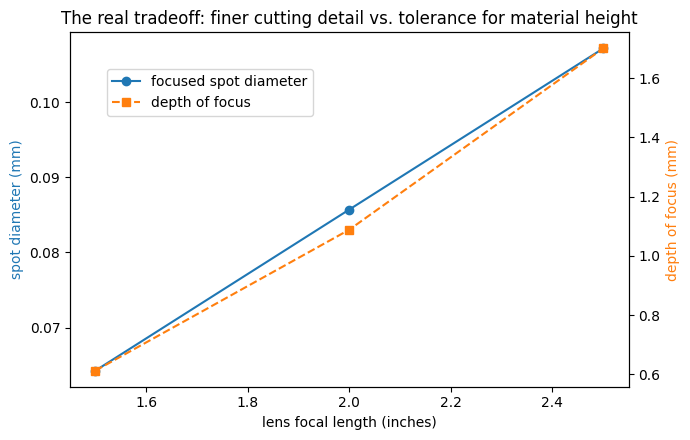

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
f_vals = [r['f_inch'] for r in results]
ax2 = ax.twinx()
ax.plot(f_vals, [r['spot_diameter_mm'] for r in results], 'o-', color='tab:blue', label='focused spot diameter')
ax2.plot(f_vals, [r['depth_of_focus_mm'] for r in results], 's--', color='tab:orange', label='depth of focus')
ax.set_xlabel('lens focal length (inches)')
ax.set_ylabel('spot diameter (mm)', color='tab:blue')
ax2.set_ylabel('depth of focus (mm)', color='tab:orange')
ax.set_title('The real tradeoff: finer cutting detail vs. tolerance for material height')
fig.legend(loc='upper left', bbox_to_anchor=(0.15, 0.85))
plt.tight_layout(); plt.show()

# Part 3 — Is a hobbyist CO2 laser actually safe to be near?

These lenses exist because CO2 laser CUTTERS need them — real hobbyist
machines run 40-80W, Class 4 by any measure. Reusing
[`dgs.laser_safety`](../dgs/laser_safety.py) directly. **One honest
caveat**: that module's demo MPE (25 W/m², see its docstring) is a
rule-of-thumb for VISIBLE-light, retinal-hazard exposure — CO2 light at
10.6µm is invisible and doesn't reach the retina at all (it's absorbed
at the cornea, a different hazard mechanism with its own, different MPE
values this module doesn't attempt to reproduce). What IS directly and
honestly true, and checked below: **10.6µm light triggers no blink or
aversion reflex whatsoever**, because the eye cannot see it — the ONE
universal protective mechanism Class 2 visible lasers rely on
(`dgs.laser_safety.is_extended_source_safe_via_blink`) simply does not
exist for this wavelength, regardless of exposure duration.

In [5]:
hobbyist_power_W = 60.0   # a common mid-range hobbyist CO2 tube rating
beam_diameter_at_source_mm = 6.0   # typical raw CO2 beam diameter before the focusing lens

E_at_source = beam_irradiance(hobbyist_power_W, beam_diameter_at_source_mm * 1e-3)
print(f"a {hobbyist_power_W:.0f}W hobbyist CO2 laser, {beam_diameter_at_source_mm}mm raw beam:")
print(f"  irradiance at the source: {E_at_source:.1f} W/m^2")
print(f"  IEC/ANSI class: {CLASS_DESCRIPTIONS['4']}")

print(f"\nCritical point about 10.6um specifically: the beam is COMPLETELY INVISIBLE.")
print(f"There is no blink/aversion response possible for a wavelength the eye cannot detect --")
print(f"the SAME formula-based protection Class 2 relies on for VISIBLE light (0.25s aversion)")
print(f"structurally cannot apply here, at ANY power level, ANY exposure duration.")
print(f"This is exactly why real CO2 laser cutters are sold as fully enclosed, interlocked systems --")
print(f"the optics this shop sells (lenses, mirrors, beam combiners) all live INSIDE that enclosure.")

a 60W hobbyist CO2 laser, 6.0mm raw beam:
  irradiance at the source: 2122065.9 W/m^2
  IEC/ANSI class: Hazardous even from a diffuse reflection; fire and skin hazard. Requires interlocked enclosure.

Critical point about 10.6um specifically: the beam is COMPLETELY INVISIBLE.
There is no blink/aversion response possible for a wavelength the eye cannot detect --
the SAME formula-based protection Class 2 relies on for VISIBLE light (0.25s aversion)
structurally cannot apply here, at ANY power level, ANY exposure duration.
This is exactly why real CO2 laser cutters are sold as fully enclosed, interlocked systems --
the optics this shop sells (lenses, mirrors, beam combiners) all live INSIDE that enclosure.


# Part 4 — Is the $46 lens actually cheaper than the $108 one?

CO2 laser lenses degrade with use (surface contamination and thermal
lensing from cutting debris) and need periodic replacement — a genuine
cost question a hobbyist actually faces, using
[`dgs.engineering_economics`](../dgs/engineering_economics.py)'s NPV
machinery on the REAL prices from Part 1. Assume the standard ZnSe lens
($46) needs replacing twice as often as the higher-grade Xenetech lens
($108) due to better coatings/quality control — checked as an NPV
comparison over a realistic ownership period, not just a per-unit price
comparison.

In [6]:
years = 4
discount_rate = 0.05   # a hobbyist's rough opportunity-cost-of-money rate
months = years * 12

# standard lens: $46, replaced every 8 months (1.5/year)
cf_standard = [0.0] * months
for t in range(0, months, 8):
    cf_standard[t] = -46.0

# Xenetech lens: $108, replaced every 16 months (half as often)
cf_xenetech = [0.0] * months
for t in range(0, months, 16):
    cf_xenetech[t] = -108.0

monthly_rate = (1 + discount_rate)**(1/12) - 1
npv_standard = npv(cf_standard, monthly_rate)
npv_xenetech = npv(cf_xenetech, monthly_rate)

print(f"over {years} years, monthly discount rate={monthly_rate:.4%} (annual {discount_rate:.0%}):")
print(f"  standard $46 lens, replaced every 8 months:  NPV of costs = ${-npv_standard:.2f}")
print(f"  Xenetech $108 lens, replaced every 16 months: NPV of costs = ${-npv_xenetech:.2f}")
cheaper = "standard" if npv_standard > npv_xenetech else "Xenetech"   # NPV of costs is negative; less negative = cheaper
print(f"\ncheaper over {years} years: the {cheaper} lens")
print(f"(per-unit price alone said standard was cheaper by ${108-46:.0f}; the replacement-adjusted",
      f"NPV comparison is the actual answer a buyer needs)")

over 4 years, monthly discount rate=0.4074% (annual 5%):
  standard $46 lens, replaced every 8 months:  NPV of costs = $254.84
  Xenetech $108 lens, replaced every 16 months: NPV of costs = $304.02

cheaper over 4 years: the standard lens
(per-unit price alone said standard was cheaper by $62; the replacement-adjusted NPV comparison is the actual answer a buyer needs)


# Part 5 — Summary

| Question | Answer |
|---|---|
| What do these real lenses (1.5"/2"/2.5") actually do to a beam? | Shorter focal length: smaller spot (finer detail), shorter depth of focus (Part 2) |
| Is a real hobbyist CO2 laser actually hazardous? | Class 4, and invisibly so — no blink protection is even possible at 10.6µm (Part 3) |
| Is the cheaper lens actually cheaper? | Depends on replacement cadence — checked via NPV, not sticker price alone (Part 4) |

Three already-built parts of this repo — beam optics, laser safety, and
engineering economics — applied to one real, live small business rather
than a synthetic example. Nothing in the physics, safety, or cost
machinery was written for this notebook; only the real product data
(fetched 2026-09-06) and the way it's plugged in are new.